In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


In [2]:
df = pd.read_csv('FinalSP.csv')

In [3]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]
x


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence
0,23,84,0,2,0,7,73,0,0,2
1,19,64,0,1,0,8,59,0,2,0
2,24,98,1,1,1,7,91,1,2,1
3,29,89,0,1,1,8,98,1,1,0
4,19,92,1,1,1,6,65,1,3,1
...,...,...,...,...,...,...,...,...,...,...
6601,25,69,2,1,0,7,76,1,1,2
6602,23,76,2,1,0,8,81,1,3,2
6603,20,90,1,0,1,6,65,0,3,0
6604,10,86,2,2,1,6,91,2,2,2


In [4]:
y

0       6.7
1       6.1
2       7.4
3       7.1
4       7.0
       ... 
6601    6.8
6602    6.9
6603    6.8
6604    6.8
6605    6.4
Name: Exam_Score, Length: 6606, dtype: float64

In [5]:
y.shape

(6606,)

In [6]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=21)

In [7]:
y_train.shape

(4954,)

In [8]:
x_train

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Tutoring_Sessions,Peer_Influence
3674,20,77,0,2,1,7,58,2,0,1
1097,8,67,2,1,1,8,58,0,2,2
3160,23,89,0,1,0,5,85,0,0,2
4759,12,71,1,0,0,8,100,1,2,1
6025,26,89,1,1,1,8,59,0,1,1
...,...,...,...,...,...,...,...,...,...,...
6512,18,68,2,0,1,8,89,1,0,0
48,22,86,0,1,1,7,72,0,3,2
772,24,91,0,0,1,7,66,2,2,1
5944,25,98,1,2,1,8,51,1,0,2


In [9]:
scaler = StandardScaler()

In [10]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [11]:
from sklearn.linear_model import LinearRegression

In [12]:
regression = LinearRegression()

In [13]:
y_train

3674    6.6
1097    6.1
3160    6.8
4759    6.3
6025    7.0
       ... 
6512    6.3
48      6.8
772     6.9
5944    7.2
5327    6.7
Name: Exam_Score, Length: 4954, dtype: float64

In [14]:
x_train.shape, y_train.shape,x_test.shape,y_test.shape

((4954, 10), (4954,), (1652, 10), (1652,))

<Axes: >

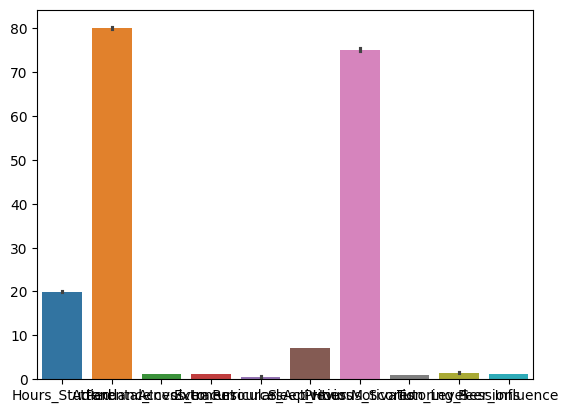

In [15]:
sns.barplot(x)

In [16]:
regression.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [17]:
regression.intercept_
regression.coef_

array([ 0.17578248,  0.2291457 ,  0.06936361,  0.07193796,  0.02633931,
       -0.00215201,  0.0678715 ,  0.03597896,  0.05894647,  0.03543148])

In [18]:
regression.predict(x_test)

array([6.75756709, 6.85592783, 6.81559614, ..., 7.79047593, 6.69478759,
       6.81031153], shape=(1652,))

In [19]:
regression.score(x_train,y_train), regression.score(x_test,y_test)

(0.6849647339926952, 0.6944235758891215)

In [20]:
y_resid = y_test-regression.predict(x_test)

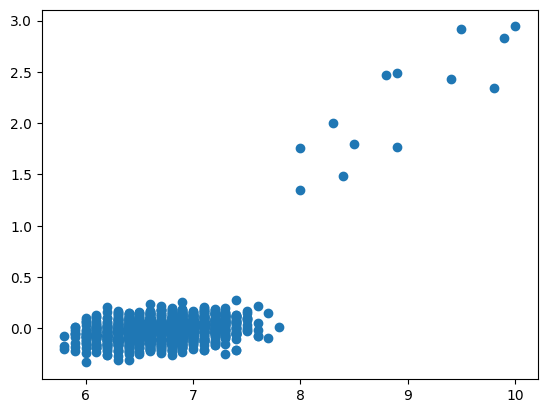

In [21]:
plt.scatter(y_test , y_resid)

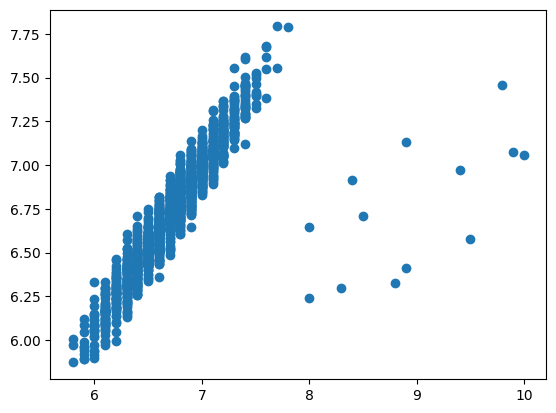

In [22]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

r2_score(y_test,regression.predict(x_test))
plt.scatter(y_test,regression.predict(x_test))

0.6944205018297854


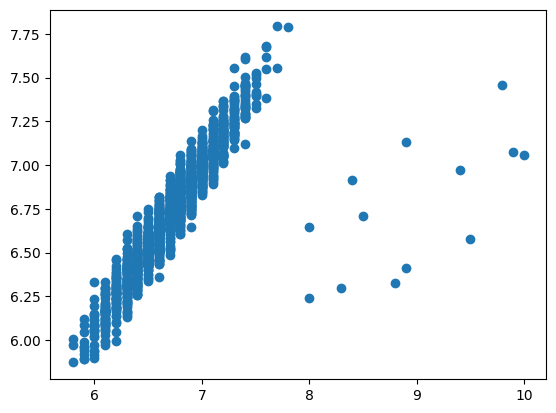

In [23]:
from sklearn.linear_model import Ridge
ridge = Ridge()
ridge.fit(x_train,y_train)
print(r2_score(y_test,ridge.predict(x_test)))
plt.scatter(y_test,ridge.predict(x_test))

-0.0004521782944322261


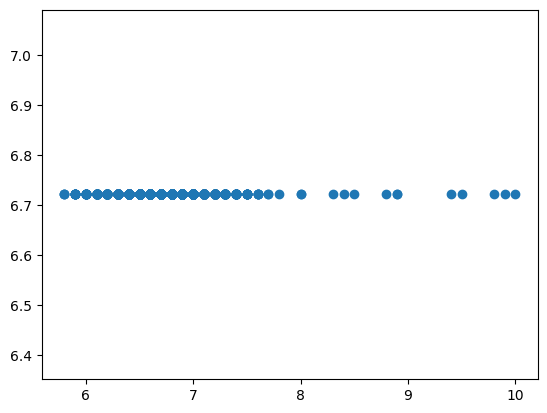

In [24]:
from sklearn.linear_model import Lasso
lasso = Lasso()
lasso.fit(x_train,y_train)
print(r2_score(y_test,lasso.predict(x_test)))
plt.scatter(y_test,lasso.predict(x_test))

0.6944232711532159


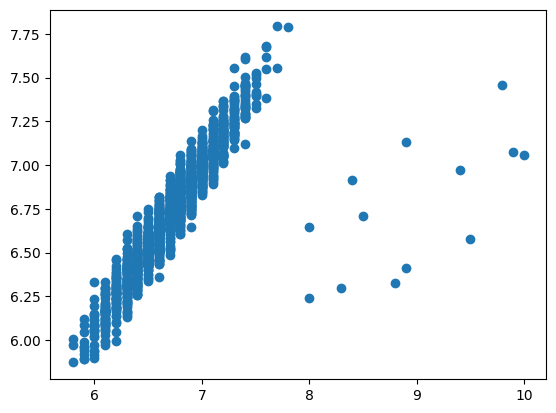

In [25]:
from sklearn.linear_model import RidgeCV
ridgecv = RidgeCV(cv=5)
ridgecv.fit(x_train,y_train)
print(r2_score(y_test,ridgecv.predict(x_test)))
plt.scatter(y_test,ridgecv.predict(x_test))

0.6943198478849736


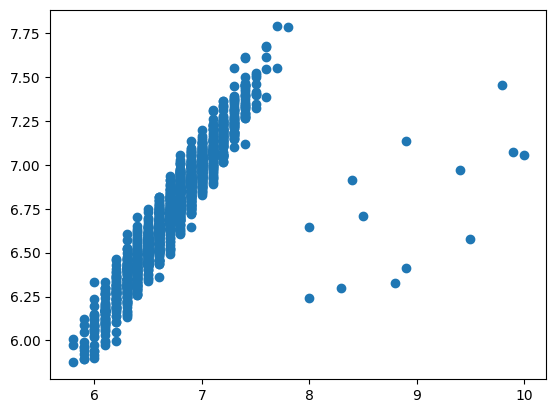

In [26]:
from sklearn.linear_model import LassoCV
lassocv = LassoCV(cv=5)
lassocv.fit(x_train,y_train)
print(r2_score(y_test,lassocv.predict(x_test)))
plt.scatter(y_test,lassocv.predict(x_test))

0.6943134161097804


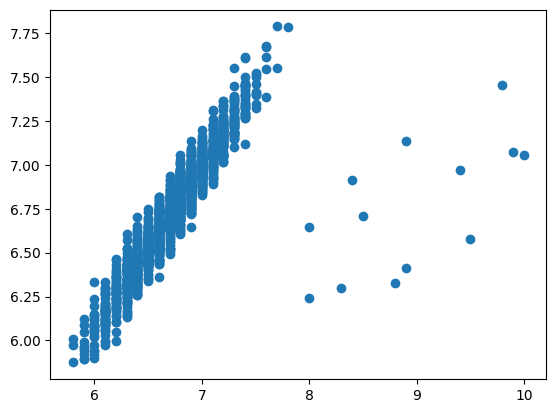

In [27]:
from sklearn.linear_model import ElasticNetCV
encv = ElasticNetCV()
encv.fit(x_train,y_train)
print(r2_score(y_test,encv.predict(x_test)))
plt.scatter(y_test,encv.predict(x_test))

In [28]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=4)

X_train_poly = poly.fit_transform(x_train)
X_test_poly = poly.transform(x_test)

model = LinearRegression()

model.fit(X_train_poly, y_train)

print("Training score:", model.score(X_train_poly, y_train))
print("Testing score:", model.score(X_test_poly, y_test))

Training score: 0.745767684670819
Testing score: 0.607239494193319


In [29]:
import pickle

pickle.dump(scaler,open("scaler.pkl","wb"))
pickle.dump(regression,open("model.pkl","wb"))

In [32]:
regression.predict(scaler.transform([[40,88,2,2,1,7,90,2,2,2]]))

C:\Users\Aryan\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([7.86446476])